# 数据分析

In [ ]:
# !pip install ultralytics

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import seaborn as sns
import cv2
import shutil
from ultralytics import YOLO
import warnings
warnings.filterwarnings('ignore')
# 关闭此 Notebook 的 Weight & Biases (wandb) 报告功能
os.environ['WANDB_DISABLED'] = 'true'

In [2]:
def get_image_files(image_directory):
    """获取指定目录中的所有 .jpg 文件"""
    return [f for f in os.listdir(image_directory) if f.endswith('.jpg')]

In [4]:
def select_random_images(jpg_files, num_images):
    """从图片文件列表中随机选择指定数量的图片"""
    return random.sample(jpg_files, num_images)

In [5]:
def create_subplots(num_images):
    """创建子图布局"""
    num_rows = int(num_images ** 0.5)
    num_cols = (num_images + num_rows - 1) // num_rows # 确保有足够的列数
    fig, axes = plt.subplots(num_rows, num_cols, figsize = (12, 12))

    # 如果只有一个子图，axes 不是数组需要转换为数组
    if num_images == 1:
        axes = [axes]
    else:
        axes = axes.flatten()
    return fig, axes

In [6]:
def display_image_with_label(ax, image_path, label_path, label_names):
    """在子图中显示图片及其对应的边界框和标签"""
    with Image.open(image_path) as img:
        width, height = img.size
        ax.imshow(img)
        ax.set_title(os.path.basename(image_path))
        ax.axis('off')

        if os.path.exists(label_path):
            with open(label_path, 'r') as label_file:
                for line in label_file:
                    label_info = line.strip().split()
                    label_id = int(label_info[0])
                    x_center, y_center, bbox_width, bbox_height = map(float, label_info[1:5])

                    # 计算边界框的左上角和右下角的坐标
                    x_min = (x_center - bbox_width / 2) * width
                    y_min = (y_center - bbox_height / 2) * height
                    x_max = (x_center + bbox_width / 2) * width
                    y_max = (y_center + bbox_height / 2) * height

                    # 绘制边界框
                    rect = plt.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min, linewidth = 2, edgecolor = 'r', facecolor = 'none')
                    ax.add_patch(rect)

                    # 显示标签名称
                    ax.text(x_min, y_min - 5, label_names[label_id], color = 'r', fontsize = 10, backgroundcolor = 'white')

In [7]:
def display_random_images_with_labels(axial_tlwce_2_class, num_images = 16):
    """主函数，调用上述函数完成整体功能"""
    # 定义标签名称
    label_names = {0: "negative", 1: "positive"}
    image_directory = os.path.join(axial_tlwce_2_class, 'images/train')
    label_directory = os.path.join(axial_tlwce_2_class, 'labels/train')

    # 获取目录中所有的 .jpg 文件
    jpg_files = get_image_files(image_directory)

    # 随机选择指定数量的图片
    selected_images = select_random_images(jpg_files, num_images)

    # 创建子图布局
    fig, axes = create_subplots(num_images)

    # 遍历选定的图片并显示在子图中
    for ax, selected_image in zip(axes, selected_images):
        image_path = os.path.join(image_directory, selected_image)
        label_path = os.path.join(label_directory, selected_image.replace('.jpg', '.txt'))
        display_image_with_label(ax, image_path, label_path, label_names)
    
    # 调整子图之间的间距
    plt.tight_layout()
    plt.show()

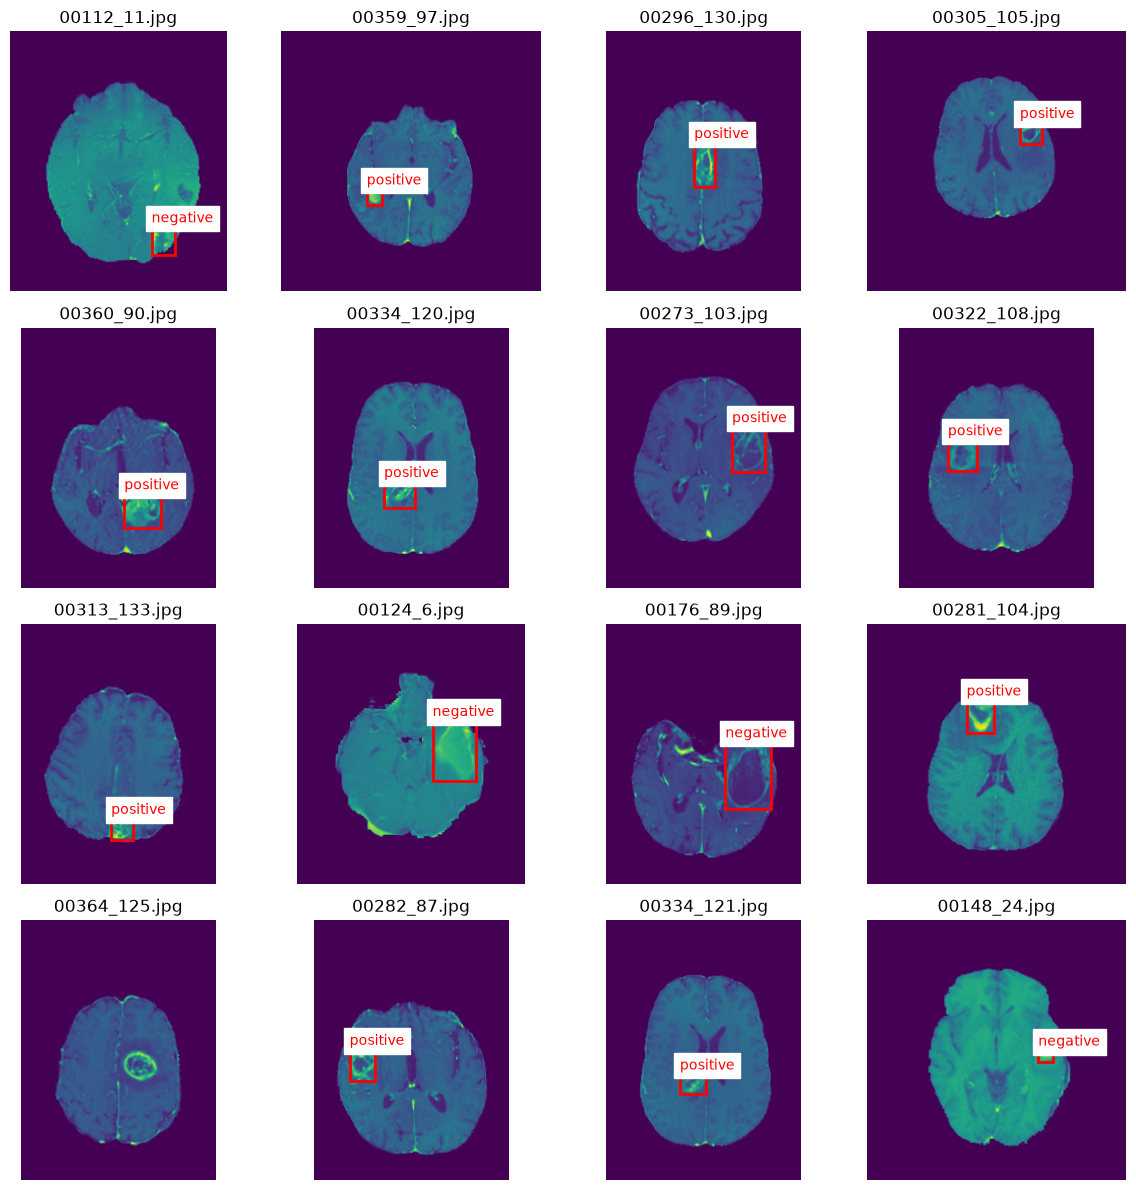

In [10]:
axial_t1wce_2 = 'archive/axial_t1wce_2_class'
display_random_images_with_labels(axial_t1wce_2, 16)

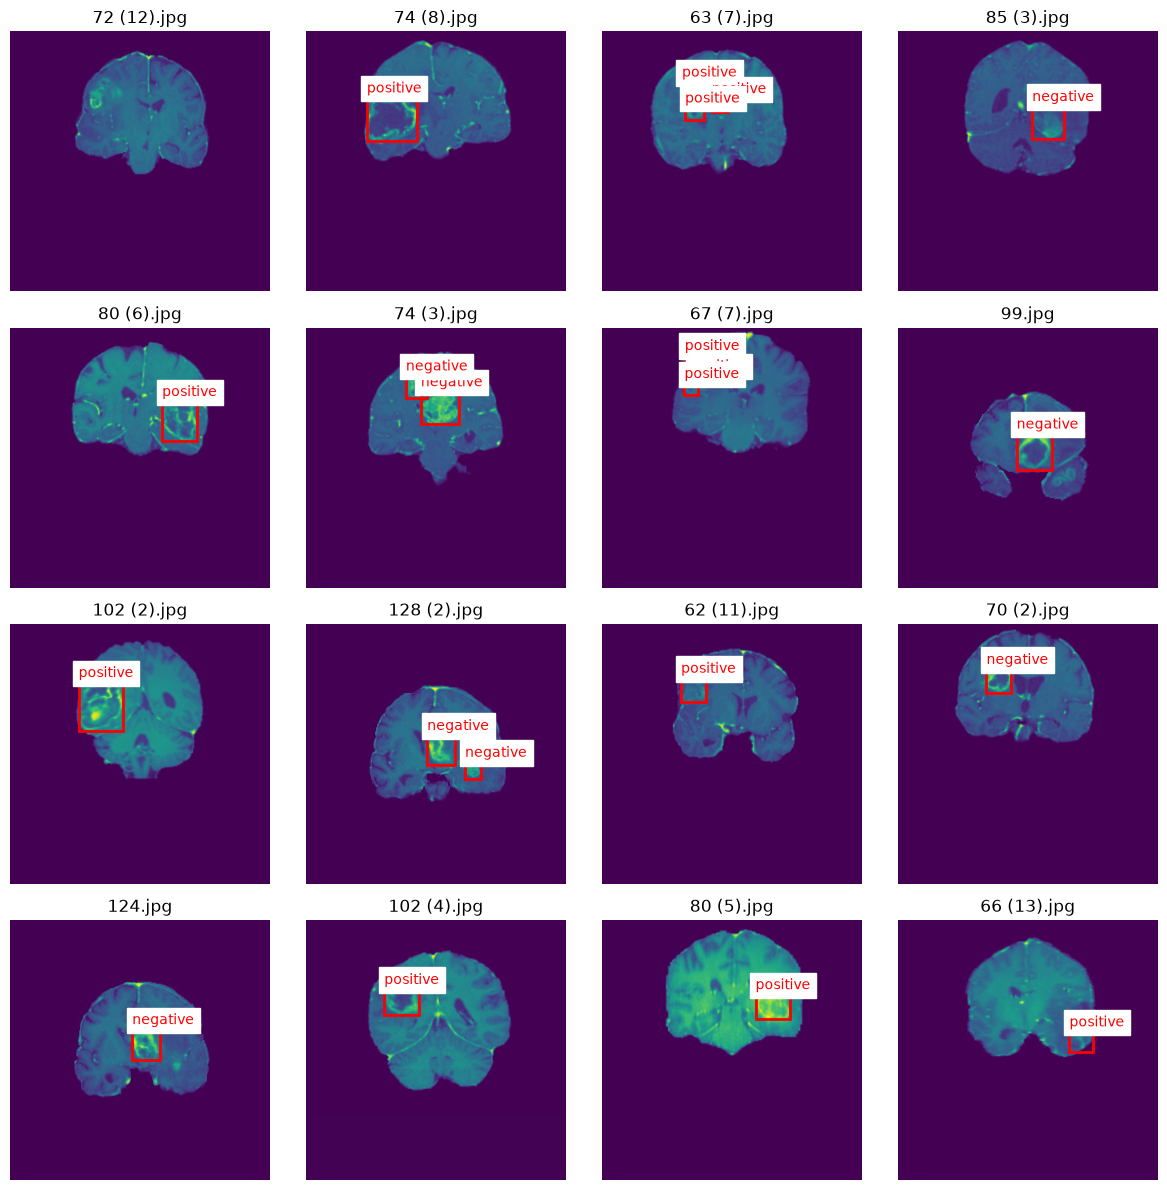

In [11]:
coronal_t1wce = 'archive/coronal_t1wce_2_class'
display_random_images_with_labels(coronal_t1wce, 16)

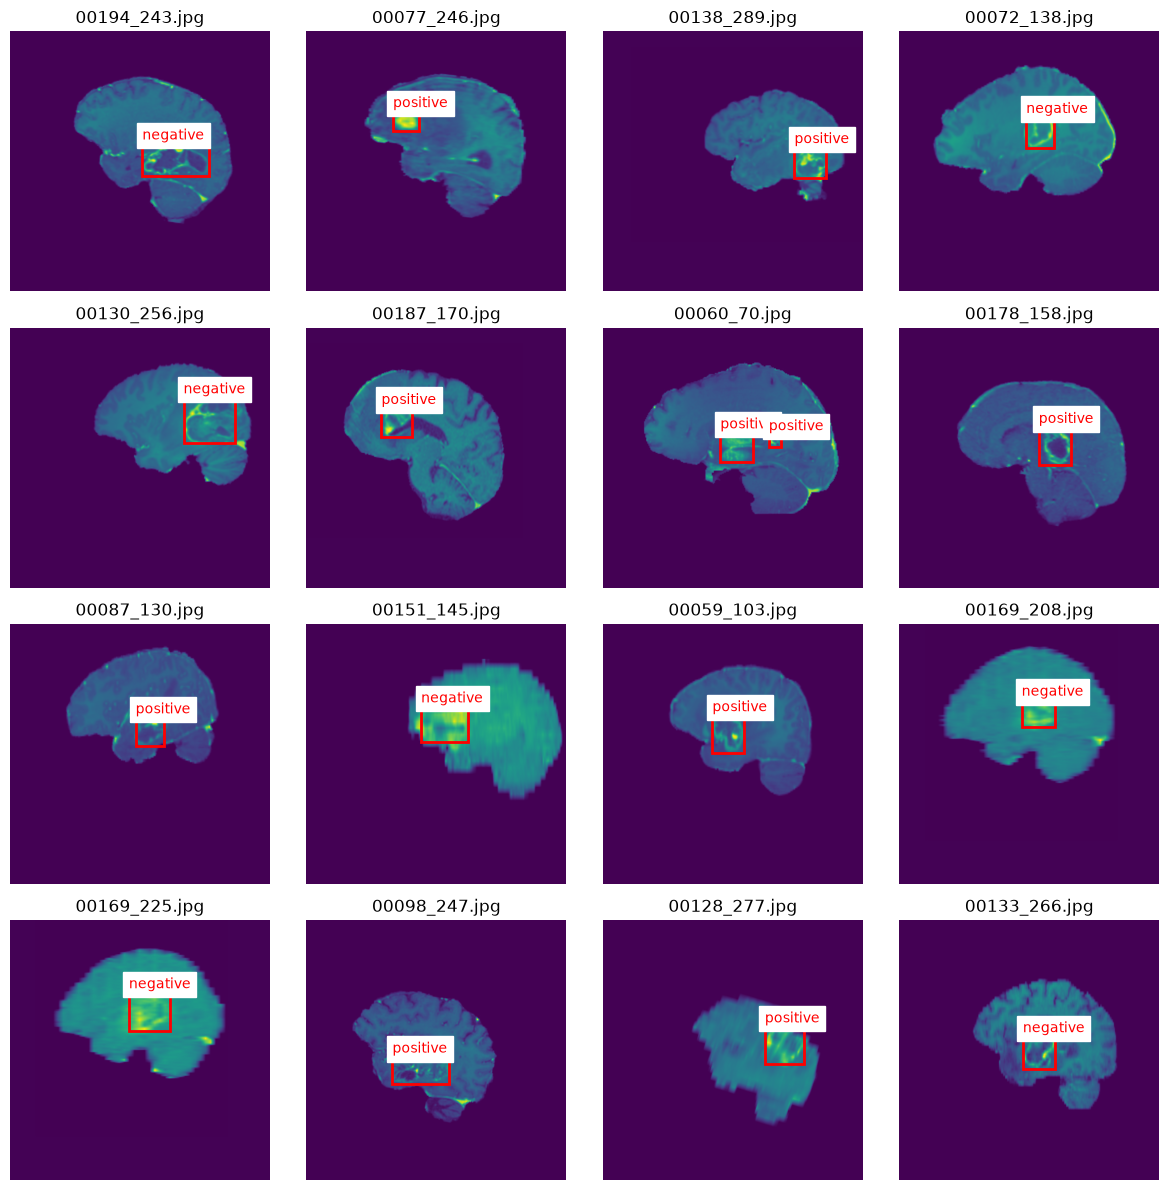

In [12]:
sagittal_t1wce = 'archive/sagittal_t1wce_2_class'
display_random_images_with_labels(sagittal_t1wce, 16)

## 数据预处理

In [18]:
def organize_datasets(source_dir, target_dir, class_names):
    """
    根据给定的源目录、目标目录和类别名称，组织数据集
    
    参数：
    source_dir (str): 源数据目录，包含所有类别的原始数据
    target_dir (str): 目标数据目录，将按照类别和用途（训练或测试）整理数据
    class_names (list of str): 数据集中的类别名称列表

    返回：
    无
    """
    # 创建目标目录结构
    for class_name in class_names:
        # 创建训练集和测试集的目录结构
        train_images_dir = os.path.join(target_dir, class_name, 'train', 'images')
        train_labels_dir = os.path.join(target_dir, class_name, 'train', 'labels')
        test_images_dir = os.path.join(target_dir, class_name, 'test', 'images')
        test_labels_dir = os.path.join(target_dir, class_name, 'test', 'labels')

        # 确保目录存在，如果不存在则创建
        os.makedirs(train_images_dir, exist_ok = True)
        os.makedirs(train_labels_dir, exist_ok = True)
        os.makedirs(test_images_dir, exist_ok = True)
        os.makedirs(test_labels_dir, exist_ok = True)

        # 复制训练集图片和标签
        source_train_images = os.path.join(source_dir, class_name, 'images', 'train')
        source_train_labels = os.path.join(source_dir, class_name, 'labels', 'train')
        # 检查源目录是否存在，如果存在则复制到目标里
        if os.path.exists(source_train_images):
            shutil.copytree(source_train_images, train_images_dir, dirs_exist_ok = True)
        if os.path.exists(source_train_labels):
            shutil.copytree(source_train_labels, train_labels_dir, dirs_exist_ok = True)
        
        # 复制测试集图片和标签
        source_test_images = os.path.join(source_dir, class_name, 'images', 'test')
        source_test_labels = os.path.join(source_dir, class_name, 'labels', 'test')
        # 同样检查源目录是否存在，如果存在则复制到目标目录
        if os.path.exists(source_test_images):
            shutil.copytree(source_test_images, test_images_dir, dirs_exist_ok = True)
        if os.path.exists(source_test_labels):
            shutil.copytree(source_test_labels, test_labels_dir, dirs_exist_ok = True)


In [20]:
source_dir = 'archive'
target_dir = 'datasets'

class_names = ['axial_t1wce_2_class', 'coronal_t1wce_2_class', 'sagittal_t1wce_2_class']
organize_datasets(source_dir, target_dir, class_names)

In [21]:
def remove_extra_images(datasets_dir):
    """
    删除 datasets 目录中 train 和 test 文件夹下 images 目录中没有对应 labels 文件的图片

    参数：
    datasets_dir (str): 包含 train 和 test 文件夹的根目录

    返回：
    无
    """
    # 遍历 train 和 test 文件夹
    for subset in ['train', 'test']:
        images_dir = os.path.join(datasets_dir, subset, 'images')
        labels_dir = os.path.join(datasets_dir, subset, 'labels')

        # 获取 labels 目录中的所有文件名（去掉扩展名）set
        label_files = {os.path.splitext(f)[0] for f in os.listdir(labels_dir) if f.endswith('.txt')}

        # 遍历 images 目录中的所有图片文件
        for image_file in os.listdir(images_dir):
            if image_file.endswith('.jpg'):
                # 去掉图片文件的扩展名，检查是否在 labels 文件集中
                image_base_name = os.path.splitext(image_file)[0]
                if image_base_name not in label_files:
                    # 如果没有对应的 labels 文件，则删除图片
                    os.remove(os.path.join(images_dir, image_file))


In [23]:
datasets_dir = [
    'datasets/axial_t1wce_2_class',
    'datasets/coronal_t1wce_2_class',
    'datasets/sagittal_t1wce_2_class'
]
for dataset_dir in datasets_dir:
    remove_extra_images(dataset_dir)

In [26]:
print('axial_t1wce_2_class 训练集的图片数量：', len(os.listdir('datasets/axial_t1wce_2_class/train/images')))
print('axial_t1wce_2_class 训练集的标签数量：', len(os.listdir('datasets/axial_t1wce_2_class/train/labels')))

print('coronal_t1wce_2_class 训练集的图片数量：', len(os.listdir('datasets/coronal_t1wce_2_class/train/images')))
print('coronal_t1wce_2_class 训练集的标签数量：', len(os.listdir('datasets/coronal_t1wce_2_class/train/labels')))

print('segittal_t1wce_2_class 训练集的图片数量：', len(os.listdir('datasets/sagittal_t1wce_2_class/train/images')))
print('segittal_t1wce_2_class 训练集的标签数量：', len(os.listdir('datasets/sagittal_t1wce_2_class/train/labels')))

axial_t1wce_2_class 训练集的图片数量： 296
axial_t1wce_2_class 训练集的标签数量： 296
coronal_t1wce_2_class 训练集的图片数量： 318
coronal_t1wce_2_class 训练集的标签数量： 318
segittal_t1wce_2_class 训练集的图片数量： 264
segittal_t1wce_2_class 训练集的标签数量： 264


In [27]:
# 将名称从 test 修改为 val
paths = [
    'datasets/axial_t1wce_2_class',
    'datasets/coronal_t1wce_2_class',
    'datasets/sagittal_t1wce_2_class'
]
for path in paths:
    os.rename(os.path.join(path, 'test'), os.path.join(path, 'val'))

In [28]:
text = """
train: ./train
val: ./val

# number of classes
nc: 2

# class names
names: ['negative', 'positive']
"""

with open('datasets/axial_t1wce_2_class/data.yaml', 'w') as file:
    file.write(text)

with open('datasets/coronal_t1wce_2_class/data.yaml', 'w') as file:
    file.write(text)

with open('datasets/sagittal_t1wce_2_class/data.yaml', 'w') as file:
    file.write(text)